## 1. 데이터 로딩 및 구조 확인

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "서울특별시 구로구_실외흡연시설_20260513"

def find_repo():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        c = p / "do_not_lung"
        if (c / "notebooks").is_dir():
            return c
    raise FileNotFoundError("do_not_lung 저장소를 찾지 못했습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_DIR = DATA_ROOT / "raw_data" / "공공데이터"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY

filenames = [
    DATASET_KEY + ".csv",
    DATASET_KEY + "(2).csv",
    DATASET_KEY + "(1).csv"
]
RAW_PATH = next(
    (RAW_DIR / n for n in filenames if (RAW_DIR / n).is_file()),
    None
)
if RAW_PATH is None:
    raise FileNotFoundError(f"원본 CSV가 없습니다: {RAW_DIR}")

for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
    try:
        raw = pd.read_csv(RAW_PATH, encoding=encoding)
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError("CSV 인코딩 확인 실패")

required = [
    "시설구분", "건물명", "도로명주소", "지번주소",
    "위도", "경도", "개수", "기준일자"
]
assert set(required).issubset(raw.columns)

print("원본:", RAW_PATH.name)
print("인코딩:", encoding)
print("행/열:", raw.shape)
print("메모리(MB):", raw.memory_usage(deep=True).sum()/1024**2)
print("pandas:", pd.__version__)
display(raw.head())
display(raw.dtypes.to_frame("dtype"))
display(raw.nunique(dropna=False).to_frame("unique_values"))

원본: 서울특별시 구로구_실외흡연시설_20260513.csv
인코딩: cp949
행/열: (48, 8)
메모리(MB): 0.0208892822265625
pandas: 3.0.6


,시설구분,건물명,도로명주소,지번주소,위도,경도,개수,기준일자
0,체육시설,고척 돔구장,서울특별시 구로구 경인로 430,서울특별시 구로구 고척동 66-47,37.498213,126.867089,6,2026-05-13
1,의료기관,구로성심병원,서울특별시 구로구 경인로 427,서울특별시 구로구 고척동 76-189,37.499647,126.866358,1,2026-05-13
2,의료기관,고대구로병원,서울특별시 구로구 구로동로 148,서울특별시 구로구 구로동 80-28,37.491180,126.884638,2,2026-05-13
3,복합건축물,지하이시티,서울특별시 구로구 디지털로 243,서울특별시 구로구 구로동 237,37.481992,126.892349,1,2026-05-13
4,복합건축물,넷마블,서울특별시 구로구 디지털로 300,서울특별시 구로구 구로동 188-25,37.484927,126.896538,1,2026-05-13


,dtype
시설구분,str
건물명,str
도로명주소,str
지번주소,str
위도,float64
경도,float64
개수,int64
기준일자,str


,unique_values
시설구분,4
건물명,48
도로명주소,47
지번주소,33
위도,43
경도,42
개수,3
기준일자,1


## 2. 결측치, 중복 및 이상치 분석

In [2]:
missing = pd.DataFrame({
    "count": raw.isna().sum(),
    "percent": raw.isna().mean() * 100
})
display(missing)

numeric = raw[["위도", "경도", "개수"]].apply(
    pd.to_numeric, errors="coerce"
)

duplicate_coord = (
    numeric.duplicated(["위도", "경도"], keep=False)
    & numeric[["위도", "경도"]].notna().all(axis=1)
)
duplicate_addr = (
    raw["지번주소"].duplicated(keep=False)
    & raw["지번주소"].notna()
)
invalid_coord = ~(
    numeric["위도"].between(33, 39)
    & numeric["경도"].between(124, 132)
)
invalid_count = (
    numeric["개수"].isna() | (numeric["개수"] <= 0)
)
invalid_date = pd.to_datetime(
    raw["기준일자"], errors="coerce"
).isna()

print("완전 중복:", raw.duplicated().sum())
print("좌표 중복 행:", duplicate_coord.sum())
print("주소 중복 행:", duplicate_addr.sum())
print("좌표 범위 오류:", invalid_coord.sum())
print("시설 수량 오류:", invalid_count.sum())
print("날짜 오류:", invalid_date.sum())
display(numeric.describe())
display(raw.loc[duplicate_coord])

,count,percent
시설구분,0,0.0
건물명,0,0.0
도로명주소,0,0.0
지번주소,0,0.0
위도,0,0.0
경도,0,0.0
개수,0,0.0
기준일자,0,0.0


완전 중복: 0
좌표 중복 행: 4
주소 중복 행: 30
좌표 범위 오류: 0
시설 수량 오류: 0
날짜 오류: 0


,위도,경도,개수
count,48.000000,48.000000,48.000000
mean,37.485556,126.892519,1.145833
std,0.005930,0.006639,0.743470
min,37.478900,126.866358,1.000000
25%,37.483012,126.891800,1.000000
50%,37.484788,126.893490,1.000000
75%,37.485957,126.896325,1.000000
max,37.509040,126.899282,6.000000


,시설구분,건물명,도로명주소,지번주소,위도,경도,개수,기준일자
33,복합건축물,에이스테크노타워1차,서울특별시 구로구 디지털로31길 38-9,서울특별시 구로구 구로동 197-48,37.4852,126.8932,1,2026-05-13
39,복합건축물,벽산디지털밸리 1차,서울특별시 구로구 디지털로27길 24,서울특별시 구로구 구로동 188-5,37.4800,126.8914,1,2026-05-13
40,복합건축물,e스페이스 타워,서울특별시 구로구 디지털로27길 24,서울특별시 구로구 구로동 188-5 (중복),37.4800,126.8914,1,2026-05-13
46,복합건축물,에이스테크노타워 1차,서울특별시 구로구 디지털로31길 38-9,서울특별시 구로구 구로동 197-48 (중복),37.4852,126.8932,1,2026-05-13


## 3. 기초 통계 및 시각화

,record_count,facility_count
시설구분,,
복합건축물,44,44
의료기관,2,3
지하철역사,1,2
체육시설,1,6


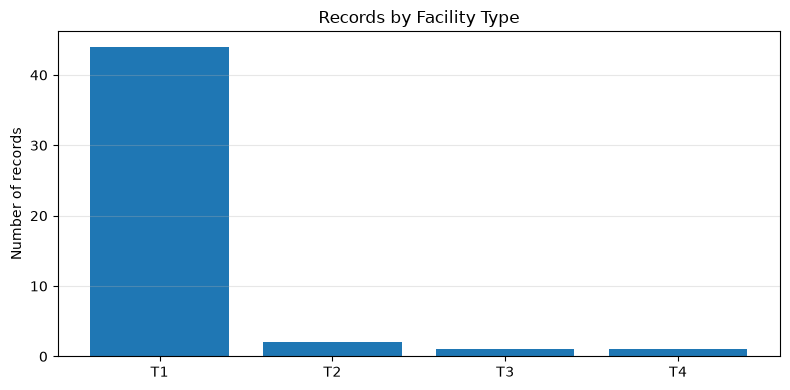

T1: 복합건축물
T2: 의료기관
T3: 지하철역사
T4: 체육시설


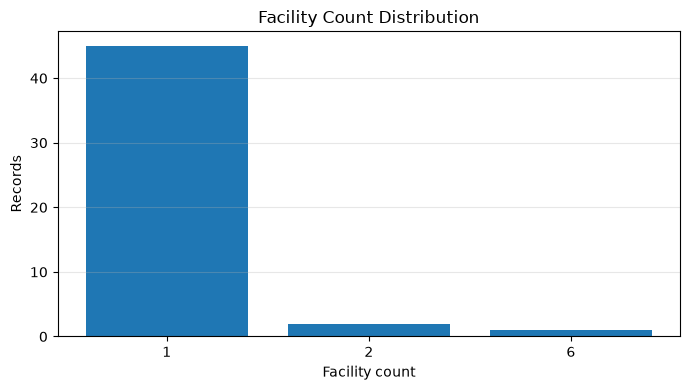

In [3]:
temp = raw.copy()
temp["개수"] = numeric["개수"]

category = (
    temp.groupby("시설구분", dropna=False)
    .agg(
        record_count=("시설구분", "size"),
        facility_count=("개수", "sum")
    )
    .sort_values("record_count", ascending=False)
)
display(category)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(category))
ax.bar(x, category["record_count"])
ax.set_xticks(x)
ax.set_xticklabels([f"T{i+1}" for i in x])
ax.set_title("Records by Facility Type")
ax.set_ylabel("Number of records")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for i, name in enumerate(category.index, 1):
    print(f"T{i}: {name}")

distribution = numeric["개수"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(distribution.index.astype(str), distribution.values)
ax.set_title("Facility Count Distribution")
ax.set_xlabel("Facility count")
ax.set_ylabel("Records")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. 좌표 기반 공간 분포

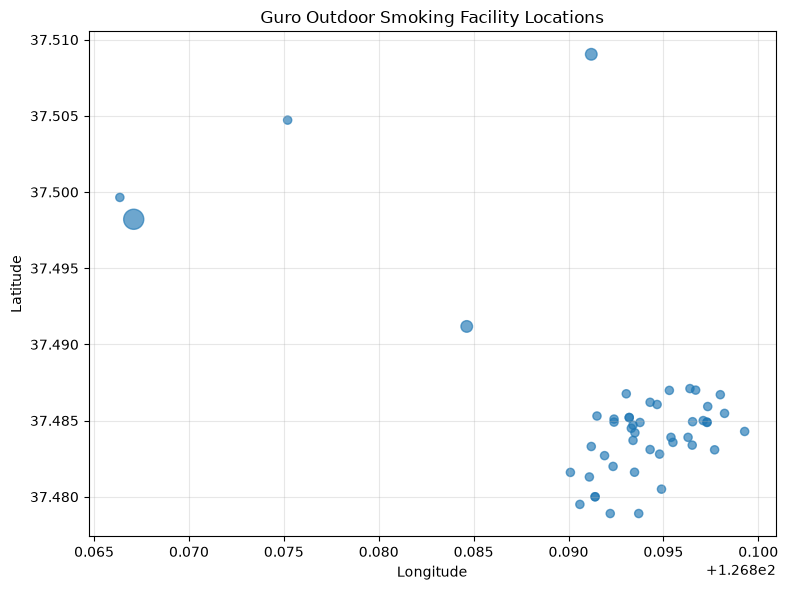

유효 좌표: 48
고유 좌표: 46
시간대 컬럼: 없음
250m 격자·도보 링크: 미결합


In [4]:
valid = ~invalid_coord

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    numeric.loc[valid, "경도"],
    numeric.loc[valid, "위도"],
    s=numeric.loc[valid, "개수"].fillna(1).clip(lower=1)*35,
    alpha=0.65
)
ax.set_title("Guro Outdoor Smoking Facility Locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("유효 좌표:", valid.sum())
print("고유 좌표:", numeric.drop_duplicates().shape[0])
print("시간대 컬럼: 없음")
print("250m 격자·도보 링크: 미결합")

## 5. 데이터 전처리

In [5]:
clean = raw.copy()
clean.insert(0, "source_row_id", np.arange(1, len(clean)+1))

for c in ["시설구분", "건물명", "도로명주소", "지번주소"]:
    clean[c] = clean[c].astype("string").str.strip()

for c in ["위도", "경도", "개수"]:
    clean[c] = pd.to_numeric(clean[c], errors="coerce")

clean["기준일자"] = pd.to_datetime(
    clean["기준일자"], errors="coerce"
).dt.strftime("%Y-%m-%d")

clean["coord_valid_broad"] = (
    clean["위도"].between(33, 39)
    & clean["경도"].between(124, 132)
).fillna(False)

clean["duplicate_coordinate_flag"] = (
    clean.duplicated(["위도", "경도"], keep=False)
    & clean[["위도", "경도"]].notna().all(axis=1)
)
clean["duplicate_address_flag"] = (
    clean["지번주소"].duplicated(keep=False)
    & clean["지번주소"].notna()
)
clean["duplicate_text_flag"] = (
    clean["지번주소"].str.contains("중복", na=False)
    | clean["도로명주소"].str.contains("중복", na=False)
)
clean["review_needed"] = (
    ~clean["coord_valid_broad"]
    | clean["duplicate_coordinate_flag"]
    | clean["duplicate_address_flag"]
    | clean["duplicate_text_flag"]
    | clean["개수"].isna()
    | (clean["개수"] <= 0)
    | clean["기준일자"].isna()
)

print("전처리 전:", raw.shape)
print("전처리 후:", clean.shape)
print("검토 필요:", int(clean["review_needed"].sum()))
display(clean.loc[clean["review_needed"]])

전처리 전: (48, 8)
전처리 후: (48, 14)
검토 필요: 32


,source_row_id,시설구분,건물명,도로명주소,지번주소,위도,경도,개수,기준일자,coord_valid_broad,duplicate_coordinate_flag,duplicate_address_flag,duplicate_text_flag,review_needed
4,5,복합건축물,넷마블,서울특별시 구로구 디지털로 300,서울특별시 구로구 구로동 188-25,37.484927,126.896538,1,2026-05-13,True,False,True,False,True
5,6,복합건축물,대륭포스트타워 1차,서울특별시 구로구 디지털로 288,서울특별시 구로구 구로동 212-8,37.483570,126.895503,1,2026-05-13,True,False,True,False,True
6,7,복합건축물,대륭포스트타워 2차,서울특별시 구로구 디지털로 306,서울특별시 구로구 구로동 182-13,37.485923,126.897336,1,2026-05-13,True,False,True,False,True
7,8,복합건축물,대륭포스트타워 3차,서울특별시 구로구 디지털로34길 27,서울특별시 구로구 구로동 182-4,37.485473,126.898223,1,2026-05-13,True,False,True,False,True
8,9,복합건축물,코오롱디지털타워빌란트,서울특별시 구로구 디지털로32길 30,서울특별시 구로구 구로동 222-7,37.483390,126.896520,1,2026-05-13,True,False,True,False,True
9,10,복합건축물,삼성아이티밸리,서울특별시 구로구 디지털로33길 27,서울특별시 구로구 구로동 197-5,37.486057,126.894669,1,2026-05-13,True,False,True,False,True
10,11,복합건축물,코오롱싸이언스밸리 2차,서울특별시 구로구 디지털로34길 55,서울특별시 구로구 구로동 811,37.484286,126.899282,1,2026-05-13,True,False,True,False,True
11,12,복합건축물,우림이비지센터 1차,서울특별시 구로구 디지털로33길 28,서울특별시 구로구 구로동 170-5,37.486982,126.895315,1,2026-05-13,True,False,True,False,True
12,13,복합건축물,이엔씨벤쳐드림타워 2차,서울특별시 구로구 디지털로33길 55,서울특별시 구로구 구로동 197-10,37.486759,126.893045,1,2026-05-13,True,False,True,False,True
13,14,복합건축물,에이스테크노타워 2차,서울특별시 구로구 디지털로31길 19,서울특별시 구로구 구로동 197-7,37.484876,126.893767,1,2026-05-13,True,False,True,False,True


## 6. summary 및 features 생성

In [6]:
rows = []

def add(section, metric, category, value, unit=""):
    rows.append({
        "section": section, "metric": metric,
        "category": category, "value": value, "unit": unit
    })

overall = {
    "raw_rows": len(raw),
    "raw_columns": len(raw.columns),
    "missing_cells": int(raw.isna().sum().sum()),
    "exact_duplicates": int(raw.duplicated().sum()),
    "unique_coordinates": len(
        clean[["위도", "경도"]].drop_duplicates()
    ),
    "duplicate_coordinate_rows": int(
        clean["duplicate_coordinate_flag"].sum()
    ),
    "duplicate_address_rows": int(
        clean["duplicate_address_flag"].sum()
    ),
    "duplicate_text_rows": int(
        clean["duplicate_text_flag"].sum()
    ),
    "invalid_coordinate_rows": int(
        (~clean["coord_valid_broad"]).sum()
    ),
    "review_needed_rows": int(clean["review_needed"].sum()),
    "facility_count_total": clean["개수"].sum()
}

for k, v in overall.items():
    add("overall", k, "", v, "count")

for name, r in category.iterrows():
    add("facility_type", "record_count", str(name),
        r["record_count"], "records")
    add("facility_type", "facility_count", str(name),
        r["facility_count"], "facilities")

for c in raw.columns:
    add("missing", "count", c, raw[c].isna().sum(), "rows")
    add("missing", "percent", c,
        raw[c].isna().mean()*100, "%")

for c in ["위도", "경도", "개수"]:
    for stat in ["min", "max", "mean", "median", "std"]:
        add("numeric", stat, c, getattr(clean[c], stat)())

summary = pd.DataFrame(rows)

features = clean[[
    "source_row_id", "시설구분", "위도", "경도",
    "개수", "duplicate_coordinate_flag", "review_needed"
]].rename(columns={
    "시설구분": "facility_type",
    "위도": "latitude",
    "경도": "longitude",
    "개수": "facility_count"
})

features = pd.get_dummies(
    features, columns=["facility_type"], dtype=int
)
display(summary.head())
display(features.head())

,section,metric,category,value,unit
0,overall,raw_rows,,48.0,count
1,overall,raw_columns,,8.0,count
2,overall,missing_cells,,0.0,count
3,overall,exact_duplicates,,0.0,count
4,overall,unique_coordinates,,46.0,count


,source_row_id,latitude,longitude,facility_count,duplicate_coordinate_flag,review_needed,facility_type_복합건축물,facility_type_의료기관,facility_type_지하철역사,facility_type_체육시설
0,1,37.498213,126.867089,6,False,False,0,0,0,1
1,2,37.499647,126.866358,1,False,False,0,1,0,0
2,3,37.491180,126.884638,2,False,False,0,1,0,0
3,4,37.481992,126.892349,1,False,False,1,0,0,0
4,5,37.484927,126.896538,1,False,True,1,0,0,0


## 7. CSV 저장 및 재읽기 검증

In [8]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "clean.csv": clean,
    "summary.csv": summary,
    "features.csv": features
}

for name, frame in outputs.items():
    frame.to_csv(
        OUT_DIR / name,
        encoding="utf-8-sig",
        index=False
    )

loaded = {}
for name, original in outputs.items():
    saved = pd.read_csv(OUT_DIR / name, encoding="utf-8-sig")
    assert saved.shape == original.shape
    assert list(saved.columns) == list(original.columns)
    loaded[name] = saved

assert loaded["clean.csv"]["source_row_id"].tolist() == (
    clean["source_row_id"].tolist()
)

for c in ["위도", "경도", "개수"]:
    assert np.allclose(
        loaded["clean.csv"][c].to_numpy(dtype=float),
        clean[c].to_numpy(dtype=float),
        equal_nan=True, atol=1e-9, rtol=0
    )

print("CSV 저장 및 검증 완료")

CSV 저장 및 검증 완료


## 8. README.md 자동 생성

In [9]:
descriptions = {
    "source_row_id": "원본 행 순서에 따라 생성한 ID",
    "시설구분": "원본 시설 유형",
    "건물명": "원본 건물 또는 시설명",
    "도로명주소": "원본 도로명주소",
    "지번주소": "원본 지번주소",
    "위도": "원본 위도",
    "경도": "원본 경도",
    "개수": "원본 시설 수량",
    "기준일자": "데이터 기준일",
    "coord_valid_broad": "광범위 좌표 범위 유효성",
    "duplicate_coordinate_flag": "중복 좌표 검토 여부",
    "duplicate_address_flag": "중복 지번주소 검토 여부",
    "duplicate_text_flag": "주소에 중복 표기 포함 여부",
    "review_needed": "데이터 품질 검토 필요 여부",
    "section": "통계 구분",
    "metric": "통계 지표",
    "category": "집계 대상 및 범주",
    "value": "통계 계산값",
    "unit": "통계값 단위",
    "latitude": "원본 위도에서 변환",
    "longitude": "원본 경도에서 변환",
    "facility_count": "원본 시설 수량에서 변환"
}

def describe(c):
    if c.startswith("facility_type_"):
        return (
            "시설 유형 원-핫 인코딩: "
            + c.removeprefix("facility_type_")
        )
    return descriptions.get(c, "추가 확인 필요")

def md_escape(v):
    return str(v).replace("|", "\\|").replace("\n", " ")

lines = [
    "# 구로구 실외흡연시설 CSV 사용 설명서",
    "",
    f"- 원본: `{RAW_PATH.name}`",
    f"- 데이터셋: `{DATASET_KEY}`",
    "- 분석 지역: 서울특별시 구로구",
    "- 기준일: " + ", ".join(
        raw["기준일자"].dropna().astype(str).unique()
    ),
    f"- 원본: {raw.shape[0]}행 × {raw.shape[1]}열",
    f"- 정제: {clean.shape[0]}행 × {clean.shape[1]}열",
    "",
    "## 전처리",
    "",
    "- 문자열 공백 제거, 숫자·날짜 형식 표준화",
    "- 원본 행 식별자와 품질 검토 플래그 생성",
    "- 중복 의심 행을 자동 삭제하지 않고 보존",
    "",
    "## CSV별 컬럼 설명",
    ""
]

purposes = {
    "clean.csv": "원본 정보 보존 및 정제",
    "summary.csv": "EDA 통계와 집계",
    "features.csv": "공간 분석·머신러닝용 변수 후보"
}

for filename, df in loaded.items():
    lines.extend([
        f"### {filename}",
        "",
        f"**목적:** {purposes[filename]}",
        f"**크기:** {len(df)}행 × {len(df.columns)}열",
        "",
        "| 컬럼명 | 자료형 | 의미 |",
        "|---|---|---|"
    ])
    for c in df.columns:
        lines.append(
            f"| `{md_escape(c)}` | `{df[c].dtype}` "
            f"| {md_escape(describe(c))} |"
        )
    lines.append("")

lines.extend([
    "## summary.csv 집계 기준",
    "",
    "- `overall`: 데이터 전체 및 품질 통계",
    "- `facility_type`: 시설 유형별 행 수와 시설 수량",
    "- `missing`: 컬럼별 결측 건수 및 비율",
    "- `numeric`: 위도·경도·개수 기술통계",
    "- 값의 단위는 `unit` 컬럼에서 확인",
    "",
    "## CSV 간 관계",
    "",
    "- `clean.csv`와 `features.csv`는 시설 등록 행 단위",
    "- 두 파일의 연결 키는 `source_row_id`",
    "- `summary.csv`는 집계 결과로 행 단위가 다름",
    "",
    "## 사용 시 주의사항",
    "",
    "- 시설 위치는 실제 흡연 발생의 정답이 아님",
    "- 등록 행 수와 시설 개수 합계를 혼동하지 말 것",
    "- 중복 좌표·주소는 검토 없이 삭제하지 말 것",
    "- 품질 플래그는 흡연 위험 점수가 아님",
    "- 좌표계·행정경계 검증이 추가로 필요함",
    "- 250m 격자와 도보 네트워크는 아직 미결합",
    "- 시간대별 흡연 발생 정보와 정답 라벨 없음",
    ""
])

readme_path = OUT_DIR / "README.md"
readme_path.write_text("\n".join(lines), encoding="utf-8")

readme_check = readme_path.read_text(encoding="utf-8")
for frame in loaded.values():
    for col in frame.columns:
        assert f"`{col}`" in readme_check

print("README.md 생성 및 검증 완료")
for p in sorted(OUT_DIR.iterdir()):
    print(p.name, p.stat().st_size, "bytes")

README.md 생성 및 검증 완료
clean.csv 9476 bytes
features.csv 2344 bytes
README.md 3736 bytes
summary.csv 2002 bytes
